      lead_source       industry employment_status       location  \
0  organic_search     technology          employed         europe   
1    social_media     technology          employed  south_america   
2        referral         retail          employed         europe   
3        paid_ads  manufacturing           student            NaN   
4        referral  manufacturing           student  north_america   

   annual_income  number_of_courses_viewed  interaction_count  lead_score  \
0        88160.0                         3                  4        0.64   
1        72688.0                         3                  7        0.72   
2        44697.0                         3                  4        0.58   
3            NaN                         3                  6        0.57   
4        24062.0                         4                  5        0.62   

   converted  
0          1  
1          1  
2          1  
3          0  
4          1  
lead_source                 148


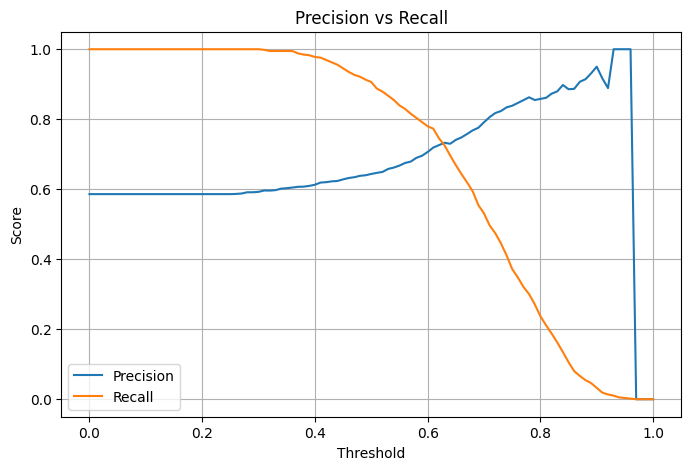

    threshold  precision    recall        f1      diff
63       0.63   0.732759  0.725256  0.728988  0.007503
62       0.62   0.725914  0.745734  0.735690  0.019820
64       0.64   0.729875  0.696246  0.712664  0.033629
Intersección precision/recall en: 0.63

=== Question 4 ===


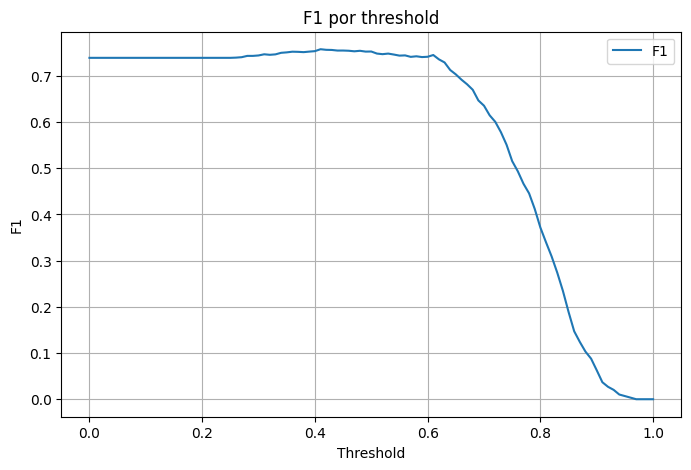

    threshold  precision    recall        f1
41       0.41   0.619048  0.976109  0.757616
42       0.42   0.620087  0.969283  0.756325
43       0.43   0.622517  0.962457  0.756032
Threshold con F1 máximo: 0.41

=== Question 5 ===
AUC por fold: [np.float64(0.731), np.float64(0.73), np.float64(0.736), np.float64(0.741), np.float64(0.721)]
Media: 0.732  Std: 0.0069

=== Question 6 ===
C=1e-06: 0.617 +- 0.019
C=0.001: 0.749 +- 0.010
C=1: 0.732 +- 0.007
Mejor C: 0.001

===== RESPUESTAS =====
Q1: lead_score
Q2: 0.732
Q3: 0.63
Q4: 0.41
Q5: 0.007
Q6: 0.001


In [1]:
# ============================================================
# ML Zoomcamp 2026 - Homework 4: Evaluation Metrics for Classification
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import roc_auc_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

# ------------------------------------------------------------
# Dataset
# ------------------------------------------------------------
url = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'
df = pd.read_csv(url)

print(df.head())
print(df.isnull().sum())

# ------------------------------------------------------------
# Data preparation
# ------------------------------------------------------------
categorical = list(df.select_dtypes(include=['object', 'string']).columns)
numerical = [c for c in df.columns if c not in categorical and c != 'converted']

df[categorical] = df[categorical].fillna('NA')
df[numerical] = df[numerical].fillna(0.0)

print('Categóricas:', categorical)
print('Numéricas:', numerical)

# ------------------------------------------------------------
# Split
# ------------------------------------------------------------
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

del df_train['converted']
del df_val['converted']
del df_test['converted']

features = categorical + numerical

# ------------------------------------------------------------
# Funciones auxiliares
# ------------------------------------------------------------
def train(df_data, y, C=1.0):
    dicts = df_data[features].to_dict(orient='records')
    dv = DictVectorizer(sparse=False)
    X = dv.fit_transform(dicts)
    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X, y)
    return dv, model

def predict(df_data, dv, model):
    dicts = df_data[features].to_dict(orient='records')
    X = dv.transform(dicts)
    return model.predict_proba(X)[:, 1]

# ------------------------------------------------------------
# Question 1: ROC AUC feature importance
# ------------------------------------------------------------
print('\n=== Question 1 ===')
auc_scores = {}
for col in numerical:
    auc = roc_auc_score(y_train, df_train[col])
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[col])
    auc_scores[col] = auc
    print(f'{col}: {auc:.4f}')

q1 = max(auc_scores, key=auc_scores.get)
print('Variable con mayor AUC:', q1)

# ------------------------------------------------------------
# Question 2: Training the model
# ------------------------------------------------------------
print('\n=== Question 2 ===')
dv, model = train(df_train, y_train, C=1.0)
y_pred = predict(df_val, dv, model)

q2 = round(roc_auc_score(y_val, y_pred), 3)
print('AUC validación:', q2)

# ------------------------------------------------------------
# Question 3: Precision and Recall
# ------------------------------------------------------------
print('\n=== Question 3 ===')
scores = []
thresholds = np.arange(0.0, 1.01, 0.01)

for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (predict_positive & actual_positive).sum()
    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0

    scores.append((round(t, 2), precision, recall, f1))

df_scores = pd.DataFrame(scores, columns=['threshold', 'precision', 'recall', 'f1'])

plt.figure(figsize=(8, 5))
plt.plot(df_scores.threshold, df_scores.precision, label='Precision')
plt.plot(df_scores.threshold, df_scores.recall, label='Recall')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Precision vs Recall')
plt.legend()
plt.grid(True)
plt.show()

valid = df_scores[(df_scores.precision > 0) | (df_scores.recall > 0)].copy()
valid['diff'] = (valid.precision - valid.recall).abs()
q3 = valid.sort_values('diff').iloc[0].threshold
print(valid.sort_values('diff').head(3))
print('Intersección precision/recall en:', q3)

# ------------------------------------------------------------
# Question 4: F1 score
# ------------------------------------------------------------
print('\n=== Question 4 ===')
plt.figure(figsize=(8, 5))
plt.plot(df_scores.threshold, df_scores.f1, label='F1')
plt.xlabel('Threshold')
plt.ylabel('F1')
plt.title('F1 por threshold')
plt.legend()
plt.grid(True)
plt.show()

q4 = df_scores.sort_values('f1', ascending=False).iloc[0].threshold
print(df_scores.sort_values('f1', ascending=False).head(3))
print('Threshold con F1 máximo:', q4)

# ------------------------------------------------------------
# Question 5: 5-Fold CV
# ------------------------------------------------------------
print('\n=== Question 5 ===')
def cross_validate(C):
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)
    aucs = []
    for train_idx, val_idx in kfold.split(df_full_train):
        df_tr = df_full_train.iloc[train_idx]
        df_va = df_full_train.iloc[val_idx]

        y_tr = df_tr.converted.values
        y_va = df_va.converted.values

        dv, model = train(df_tr, y_tr, C=C)
        y_pred_va = predict(df_va, dv, model)
        aucs.append(roc_auc_score(y_va, y_pred_va))
    return np.mean(aucs), np.std(aucs), aucs

mean_auc, std_auc, fold_aucs = cross_validate(C=1.0)
print('AUC por fold:', [round(a, 3) for a in fold_aucs])
print(f'Media: {mean_auc:.3f}  Std: {std_auc:.4f}')
q5 = round(std_auc, 3)

# ------------------------------------------------------------
# Question 6: Hyperparameter Tuning
# ------------------------------------------------------------
print('\n=== Question 6 ===')
results = []
for C in [0.000001, 0.001, 1]:
    mean_auc, std_auc, _ = cross_validate(C=C)
    results.append((C, round(mean_auc, 3), round(std_auc, 3)))
    print(f'C={C}: {mean_auc:.3f} +- {std_auc:.3f}')

# Mejor media; en empate, menor std; luego menor C
results.sort(key=lambda x: (-x[1], x[2], x[0]))
q6 = results[0][0]
print('Mejor C:', q6)

# ------------------------------------------------------------
# Resumen de respuestas
# ------------------------------------------------------------
print('\n===== RESPUESTAS =====')
print('Q1:', q1)
print('Q2:', q2)
print('Q3:', q3)
print('Q4:', q4)
print('Q5:', q5)
print('Q6:', q6)
